In [ ]:
import numpy as np
import pandas as pd
import os

np.random.seed(42)

n = 250 

tiempo_pg = np.random.gamma(shape=2.5, scale=12, size=n) + 20
tiempo_mongo = np.random.gamma(shape=2.0, scale=14, size=n) + 15

df = pd.DataFrame({
    'tiempo_ms': np.concatenate([tiempo_pg, tiempo_mongo]),
    'motor': ['PostgreSQL'] * n + ['MongoDB'] * n
})

# Redondear a 2 decimales 
df['tiempo_ms'] = df['tiempo_ms'].round(2)

archivo_salida = 'data/dataset_C_B.csv'
df.to_csv(archivo_salida, index=False)

print(f"Dataset generado exitosamente con {len(df)} registros en '{archivo_salida}'.")

Dataset generado exitosamente con 500 registros en 'data/dataset_C_B.csv'.


--- Información del Dataset ---
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   tiempo_ms  500 non-null    float64
 1   motor      500 non-null    str    
dtypes: float64(1), str(1)
memory usage: 12.1 KB

Valores nulos por columna:
 tiempo_ms    0
motor        0
dtype: int64

Registros totales tras la limpieza: 483

--- Estadísticas Descriptivas ---


,Media,Mediana,Desv_Estandar,Varianza,Asimetria,Curtosis
motor,,,,,,
MongoDB,40.16,36.45,16.01,256.34,0.82,-0.00
PostgreSQL,48.53,46.40,14.92,222.73,0.62,-0.14


C:\Users\david\AppData\Local\Temp\ipykernel_15888\3816118231.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_limpio, x='motor', y='tiempo_ms', ax=ax[1], palette='Set2')


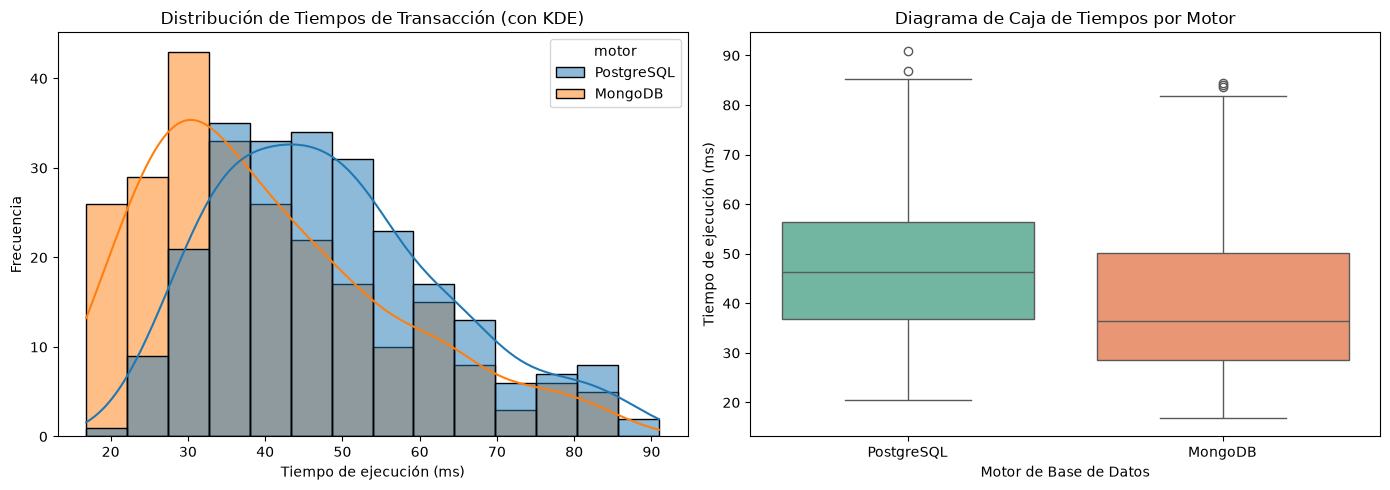

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis

df = pd.read_csv('data/dataset_C_B.csv')
print("--- Información del Dataset ---")
df.info()
print("\nValores nulos por columna:\n", df.isnull().sum())

Q1 = df.groupby('motor')['tiempo_ms'].transform(lambda x: x.quantile(0.25))
Q3 = df.groupby('motor')['tiempo_ms'].transform(lambda x: x.quantile(0.75))
IQR = Q3 - Q1

limite_inf = Q1 - 1.5 * IQR
limite_sup = Q3 + 1.5 * IQR

df_limpio = df[(df['tiempo_ms'] >= limite_inf) & (df['tiempo_ms'] <= limite_sup)]
print(f"\nRegistros totales tras la limpieza: {len(df_limpio)}")

estadisticas = df_limpio.groupby('motor')['tiempo_ms'].agg([
    ('Media', 'mean'),
    ('Mediana', 'median'),
    ('Desv_Estandar', 'std'),
    ('Varianza', 'var'),
    ('Asimetria', lambda x: skew(x, bias=False)),
    ('Curtosis', lambda x: kurtosis(x, bias=False))
]).round(2)

print("\n--- Estadísticas Descriptivas ---")
display(estadisticas)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=df_limpio, x='tiempo_ms', hue='motor', kde=True, ax=ax[0], alpha=0.5)
ax[0].set_title('Distribución de Tiempos de Transacción (con KDE)')
ax[0].set_xlabel('Tiempo de ejecución (ms)')
ax[0].set_ylabel('Frecuencia')

sns.boxplot(data=df_limpio, x='motor', y='tiempo_ms', ax=ax[1], palette='Set2')
ax[1].set_title('Diagrama de Caja de Tiempos por Motor')
ax[1].set_xlabel('Motor de Base de Datos')
ax[1].set_ylabel('Tiempo de ejecución (ms)')

plt.tight_layout()
plt.show()

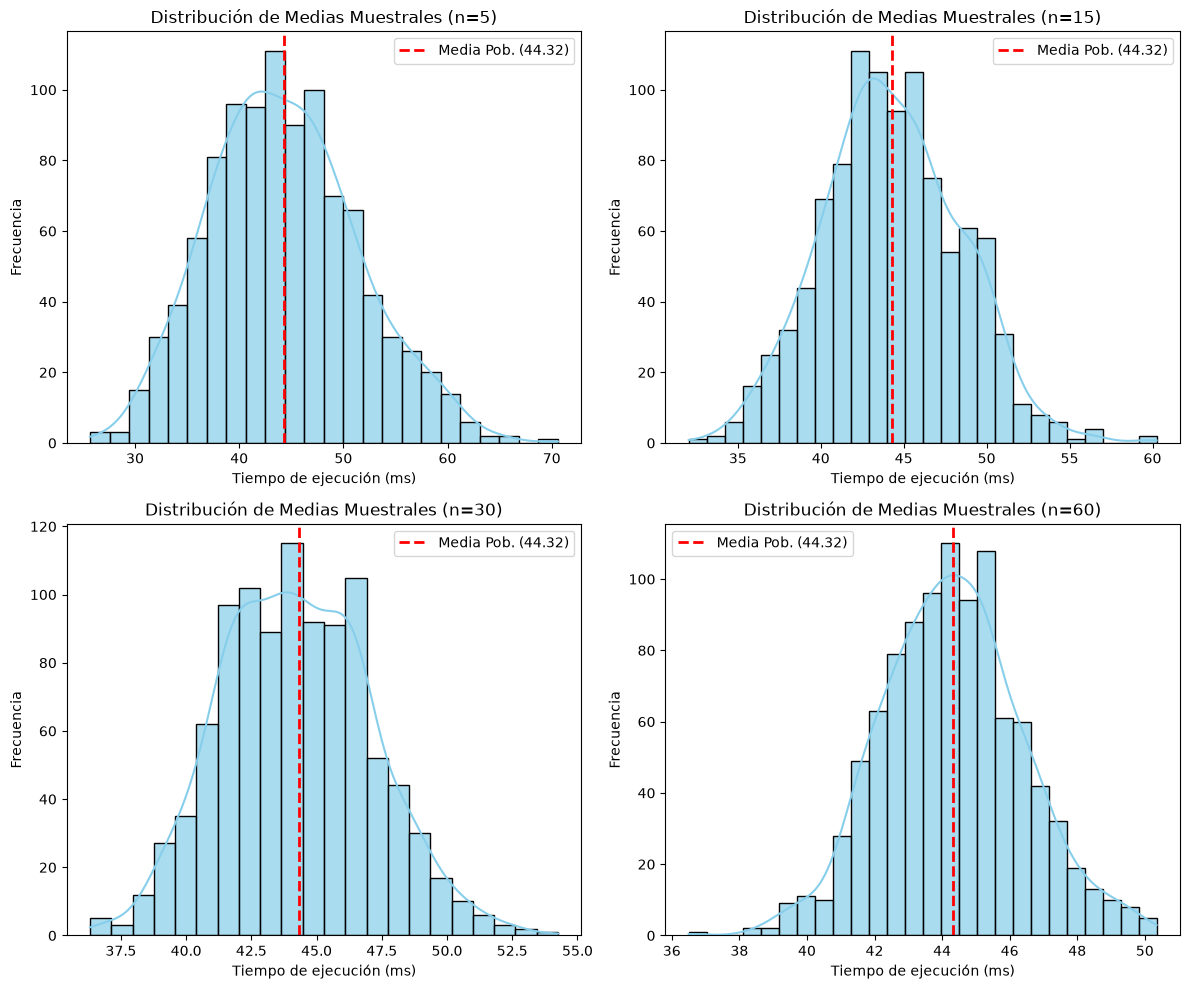

--- Verificación del Error Estándar y Convergencia ---
Tamaño de muestra n=5:
  SE Empírico : 7.1304
  SE Teórico  : 7.1576
----------------------------------------
Tamaño de muestra n=15:
  SE Empírico : 4.1405
  SE Teórico  : 4.1324
----------------------------------------
Tamaño de muestra n=30:
  SE Empírico : 2.8795
  SE Teórico  : 2.9221
----------------------------------------
Tamaño de muestra n=60:
  SE Empírico : 2.0774
  SE Teórico  : 2.0662
----------------------------------------


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

poblacion = df_limpio['tiempo_ms'].values
media_poblacional = np.mean(poblacion)
desv_estandar_poblacional = np.std(poblacion, ddof=0)

tamanos_muestra = [5, 15, 30, 60]
iteraciones = 1000
resultados_medias = {}

np.random.seed(42) 

for n in tamanos_muestra:
    medias_muestrales = [np.mean(np.random.choice(poblacion, size=n, replace=True)) for _ in range(iteraciones)]
    resultados_medias[n] = medias_muestrales

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, n in enumerate(tamanos_muestra):
    ax = axes[i]
    sns.histplot(resultados_medias[n], kde=True, ax=ax, color='skyblue', alpha=0.7)
    ax.axvline(media_poblacional, color='red', linestyle='dashed', linewidth=2, 
               label=f'Media Pob. ({media_poblacional:.2f})')
    ax.set_title(f'Distribución de Medias Muestrales (n={n})')
    ax.set_xlabel('Tiempo de ejecución (ms)')
    ax.set_ylabel('Frecuencia')
    ax.legend()

plt.tight_layout()
plt.show()

print("--- Verificación del Error Estándar y Convergencia ---")
for n in tamanos_muestra:
    # Error empírico de las 1,000 medias generadas
    error_estandar_empirico = np.std(resultados_medias[n], ddof=1)
    # Fórmula teórica del Error Estándar (Sigma / raíz de n)
    error_estandar_teorico = desv_estandar_poblacional / np.sqrt(n)
    
    print(f"Tamaño de muestra n={n}:")
    print(f"  SE Empírico : {error_estandar_empirico:.4f}")
    print(f"  SE Teórico  : {error_estandar_teorico:.4f}")
    print("-" * 40)

In [5]:
import numpy as np
import scipy.stats as stats

# 1. Intervalos de Confianza para la media poblacional general (mu)
datos_globales = df_limpio['tiempo_ms']
n_global = len(datos_globales)
media_global = np.mean(datos_globales)
error_est_global = stats.sem(datos_globales) 
grados_libertad = n_global - 1

print("--- 1. IC para la Media Poblacional General ---")

niveles = [0.90, 0.95, 0.99]
for conf in niveles:
    # Usamos stats.t.interval para aplicar la distribución t-Student
    limite_inf, limite_sup = stats.t.interval(confidence=conf, df=grados_libertad, 
                                              loc=media_global, scale=error_est_global)
    print(f"IC al {int(conf*100)}%: [{limite_inf:.2f} ms, {limite_sup:.2f} ms]")

# 2. Prueba de Levene para homogeneidad de varianzas
tiempo_pg = df_limpio[df_limpio['motor'] == 'PostgreSQL']['tiempo_ms']
tiempo_mongo = df_limpio[df_limpio['motor'] == 'MongoDB']['tiempo_ms']

est_levene, p_valor_levene = stats.levene(tiempo_pg, tiempo_mongo)
print("\n--- 2. Prueba de Levene (Homogeneidad de Varianzas) ---")
print(f"Estadístico: {est_levene:.4f}, p-value: {p_valor_levene:.4f}")

varianzas_iguales = p_valor_levene > 0.05

# 3. IC para la Diferencia de Medias (mu_pg - mu_mongo) al 95%
n_pg = len(tiempo_pg)
n_mongo = len(tiempo_mongo)
media_pg = np.mean(tiempo_pg)
media_mongo = np.mean(tiempo_mongo)
var_pg = np.var(tiempo_pg, ddof=1)
var_mongo = np.var(tiempo_mongo, ddof=1)

diferencia_medias = media_pg - media_mongo

# Lógica para aplicar Welch o Varianza Combinada según la prueba de Levene
if varianzas_iguales:
    sp = np.sqrt(((n_pg - 1) * var_pg + (n_mongo - 1) * var_mongo) / (n_pg + n_mongo - 2))
    se_dif = sp * np.sqrt(1/n_pg + 1/n_mongo)
    df_dif = n_pg + n_mongo - 2
else:
    se_dif = np.sqrt(var_pg/n_pg + var_mongo/n_mongo)
    df_dif = (var_pg/n_pg + var_mongo/n_mongo)**2 / ((var_pg/n_pg)**2 / (n_pg-1) + (var_mongo/n_mongo)**2 / (n_mongo-1))

t_critico = stats.t.ppf(1 - 0.025, df_dif) # Nivel de confianza del 95% (alpha/2)
margen_error = t_critico * se_dif

ic_dif_inf = diferencia_medias - margen_error
ic_dif_sup = diferencia_medias + margen_error

print("\n--- 3. IC para la Diferencia de Medias (PostgreSQL - MongoDB) al 95% ---")
print(f"Diferencia puntual de medias: {diferencia_medias:.2f} ms")
print(f"Intervalo de Confianza 95%: [{ic_dif_inf:.2f} ms, {ic_dif_sup:.2f} ms]")

# Evaluar la presencia del cero en el intervalo
cero_en_ic = ic_dif_inf <= 0 <= ic_dif_sup
print(f"\n¿El cero pertenece al intervalo (0 en IC)? {'Sí' if cero_en_ic else 'No'}")

--- 1. IC para la Media Poblacional General ---
IC al 90%: [43.11 ms, 45.52 ms]
IC al 95%: [42.88 ms, 45.75 ms]
IC al 99%: [42.43 ms, 46.20 ms]

--- 2. Prueba de Levene (Homogeneidad de Varianzas) ---
Estadístico: 0.7428, p-value: 0.3892

--- 3. IC para la Diferencia de Medias (PostgreSQL - MongoDB) al 95% ---
Diferencia puntual de medias: 8.37 ms
Intervalo de Confianza 95%: [5.60 ms, 11.14 ms]

¿El cero pertenece al intervalo (0 en IC)? No


In [6]:
import scipy.stats as stats

print("--- 1. Planteamiento de Hipótesis ---")
print("H0 (Nula): No hay diferencia en el tiempo medio de transacción entre PostgreSQL y MongoDB (mu_pg = mu_mongo).")
print("H1 (Alternativa): Existe una diferencia significativa en el tiempo medio (mu_pg != mu_mongo).\n")

# Ejecutar la prueba T para muestras independientes (usando equal_var=True debido a la prueba de Levene previa)
t_stat, p_valor_ttest = stats.ttest_ind(tiempo_pg, tiempo_mongo, equal_var=True)

print("--- 2. Ejecución de Prueba Paramétrica (T-Test) ---")
print(f"Nivel de significancia establecido: alpha = 0.05")
print(f"Estadístico T: {t_stat:.4f}")
print(f"P-Value: {p_valor_ttest:.4e}") # Formato científico por ser un número muy pequeño

print("\n--- 3. Veredicto y Declaración Formal ---")
if p_valor_ttest < 0.05:
    print("Veredicto: RECHAZAR la Hipótesis Nula (H0).")
    print("Conclusión Técnica: Se comprueba estadísticamente que los tiempos de ejecución de transacciones")
    print("difieren significativamente entre PostgreSQL y MongoDB.")
else:
    print("Veredicto: NO RECHAZAR la Hipótesis Nula (H0).")
    print("Conclusión Técnica: No existe evidencia suficiente para afirmar que un motor")
    print("es más rápido que el otro en el escenario simulado.")

--- 1. Planteamiento de Hipótesis ---
H0 (Nula): No hay diferencia en el tiempo medio de transacción entre PostgreSQL y MongoDB (mu_pg = mu_mongo).
H1 (Alternativa): Existe una diferencia significativa en el tiempo medio (mu_pg != mu_mongo).

--- 2. Ejecución de Prueba Paramétrica (T-Test) ---
Nivel de significancia establecido: alpha = 0.05
Estadístico T: 5.9403
P-Value: 5.4600e-09

--- 3. Veredicto y Declaración Formal ---
Veredicto: RECHAZAR la Hipótesis Nula (H0).
Conclusión Técnica: Se comprueba estadísticamente que los tiempos de ejecución de transacciones
difieren significativamente entre PostgreSQL y MongoDB.
